In [38]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection, LineCollection, Collection
from matplotlib.path import Path
from mpl_toolkits.mplot3d import Axes3D

from scipy.stats import pearsonr, spearmanr
import math
import torch
import gpytorch
from matplotlib import pyplot as plt
import plotly.graph_objects as go

import seaborn as sns
from scipy.spatial import ConvexHull, convex_hull_plot_2d

import pandas as pd
import trimesh

#%matplotlib inline
%matplotlib widget
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Load data

In [42]:
data_dict = {}
for f in os.listdir('.'):
    if 'npy' in f:
        data_dict[f] = np.load(f)

df1 = pd.read_excel('DiagnosticLaparoscopy_UnknownPathology_2021-18-10--14-48-56.xls')
df2 = pd.read_excel('DiagnosticLaparoscopy_UnknownPathology_2021-18-10--14-48-57.xls')

print(df1[df1['Total score'] >= 145]['Attachments:'])
print(df2[df2['Total score'] >= 145]['Attachments:'])

9     3db9106b-868c-4b3f-97aa-8f4da1a26ffb.gz
11    046d2dd1-9545-4205-b054-666c8f793b61.gz
23    b2f576d1-1f28-47bc-b669-8be76ed0fe39.gz
25    5a221663-1fbb-4c38-8226-61da67fe13c7.gz
45    cb866782-61f1-4c2b-bd6c-101de4e1be56.gz
73    96a0b263-f925-4676-9c6f-88f57f9da335.gz
Name: Attachments:, dtype: object
8     2add548a-8876-42a6-b82b-73875f65754b.gz
9     f340543f-db3f-43b3-aa04-df6c86228921.gz
13    a721bb89-e3bf-4773-a6e3-48b89bb60a5e.gz
15    7b543c6a-5f21-446d-a12a-e958b0bbe07d.gz
21    dcca7593-d38a-41f6-9717-f335a45baacd.gz
23    9891a4c6-aec7-420a-b606-34ea5662805e.gz
43    1552c740-2f6e-43fc-9801-c8f242bddf92.gz
54    bbc3e1d2-60e8-4608-bd66-1bf8661ef19a.gz
55    1d9b634d-7b7c-47b2-8b2b-51920aad6429.gz
56    a79433e1-be7b-461d-8b03-b1170eda43cd.gz
Name: Attachments:, dtype: object


In [20]:
idx = np.arange(3000,3050)
X = []
for k,v in data_dict.items():
    X.append(v[idx,:3])
    
train_y = torch.FloatTensor(np.array(X).reshape(-1,3))
train_x = torch.FloatTensor(torch.linspace(0, 1, train_y.shape[0]))

### Load objects

In [21]:
def load_obj(fname):
    V, F = [], []
    with open(fname) as f:
        for line in f.readlines():
            if line.startswith('#'):  
                continue
            values = line.split()
            if not values:            
                continue
            if values[0] == 'v':      
                V.append([float(x) for x in values[1:4]])
            elif values[0] == 'f' :
                if '/' in line:
                    F.append([int(x.split('/')[0]) for x in values[1:4]])
                else:
                    F.append([int(x) for x in values[1:4]])

    V, F = np.array(V)*100, np.array(F)-1
    
    return V,F

def as_mesh(scene_or_mesh):
    """
    Convert a possible scene to a mesh.

    If conversion occurs, the returned mesh has only vertex and face data.
    """
    if isinstance(scene_or_mesh, trimesh.Scene):
        if len(scene_or_mesh.geometry) == 0:
            mesh = None  # empty scene
        else:
            # we lose texture information here
            mesh = trimesh.util.concatenate(
                tuple(trimesh.Trimesh(vertices=g.vertices, faces=g.faces)
                      for g in scene_or_mesh.geometry.values()))
    else:
        assert(isinstance(scene_or_mesh, trimesh.Trimesh))
        mesh = scene_or_mesh
    return mesh

def load_mesh_tri(fname, simplify_mesh=False, scale=100):

    mesh = as_mesh(trimesh.load_mesh(fname))
    mesh.apply_scale(scale)
    if simplify_mesh and 'Belly' not in f:
        mesh = mesh.simplify_quadratic_decimation(2000)

    # apply gravity shift on everything but Belly
    if 'Belly' in fname:
        return mesh.vertices, mesh
    else:
        return mesh.vertices + np.tile((0,-2,0),(mesh.vertices.shape[0],1)), mesh

#V1, _ = load_mesh_tri('obj/LiverRight.obj')
#V2, _ = load_obj('obj/LiverRight.obj')

#fig = plt.figure(figsize=[7,7])
#ax = fig.add_subplot(111, projection='3d')
#ax.view_init(-45, 90)
#ax.set_xlabel('x')
#ax.set_ylabel('y')
#ax.set_zlabel('z')

#ax.scatter(V1[:,0],V1[:,1]+9.8,V1[:,2],s=0.2,marker='+')
#ax.scatter(V2[:,0],V2[:,1]+9.8,V2[:,2],s=0.2,marker='*')

#ax.scatter(V2[0][:,0],V2[0][:,1]+9.8,V2[0][:,2],s=0.1)

In [23]:
obj_dict = {}
for f in os.listdir('obj'):
    if '.obj' in f:
        #obj_dict[f] = load_obj(os.path.join('obj',f))
        obj_dict[f] = load_mesh_tri(os.path.join('obj',f), simplify_mesh=False)
        print(f, len(obj_dict[f][0]))



Spleen.obj 2004
ColonTop.obj 3652
LiverLeft.obj 3046
SmallerIntestine.obj 23089
ColonRight.obj 1050
CecumAppendix.obj 1649
ColonLeftRectum.obj 2278
GreaterOmentum.obj 5630
Stomach.obj 4630
Falciform.obj 1391
LiverRight.obj 5053
Belly.obj 5847
HepatoDuodenalLigament.obj 1664
GallBladder.obj 855
DomeOfBladder.obj 807
Uterus.obj 1662


In [14]:
def plt_sphere(ax, list_center, list_radius, color, smoothness=50j):
    for c, r in zip(list_center, list_radius):

        # draw sphere
        u, v = np.mgrid[0:2*np.pi:smoothness, 0:np.pi:smoothness]
        x = r*np.cos(u)*np.sin(v)
        y = r*np.sin(u)*np.sin(v)
        z = r*np.cos(v)

        ax.plot_surface(x+c[0], y+c[1], z+c[2], color=color, alpha=0.1)
        
def plt_sphere_2(ax, list_center, list_radius, color, q = 0.5, p = 0.8):
    for c, r in zip(list_center, list_radius):     
        u = np.linspace(0, 2 * np.pi, 100)
        v = np.linspace(q, p * np.pi, int(p*100))
        x = r * np.outer(np.cos(u), np.sin(v)) + c[0]
        y = r * np.outer(np.sin(u), np.sin(v)) + c[1]
        z = r * np.outer(np.ones(np.size(u)), np.cos(v)) + c[2]
        ax.plot_surface(x, y, z, color=color, alpha=0.1)

def plt_sphere_section(ax, list_center, list_radius, color, u_range = (1.0,2.0),  v_range = (1.0,2.0)):
    for c, r in zip(list_center, list_radius):     
        #u = np.linspace(0, 2*np.pi, 100)
        #v = np.linspace(0, 2*np.pi, 100)
        
        # draw sphere
        u = np.linspace(0, 2 * np.pi, 100)
        v = np.linspace(0, np.pi, 100)
        
        u_ = u[(u > u_range[0]) & (u < u_range[1])]
        v_ = v[(v > v_range[0]) & (v < v_range[1])]
        
        x = r * np.outer(np.cos(u_), np.sin(v_)) + c[0]
        y = r * np.outer(np.sin(u_), np.sin(v_)) + c[1]
        z = r * np.outer(np.ones(np.size(u_)), np.cos(v_)) + c[2]
        ax.plot_surface(x, y, z, color=color, alpha=0.1)
        
def check_inside_shell(state, c, r1, r2, theta_bounds=None, phi_bounds=None):
    if theta_bounds is None and phi_bounds is None:
        return np.linalg.norm(state-c) > r1 and np.linalg.norm(state-c) < r2
    else:
        state_ = state-c
        radius_condition = np.linalg.norm(state_) > r1 and np.linalg.norm(state_) < r2
        theta_ = np.arccos(state_[-1]/np.linalg.norm(state_))
        theta_condition = theta_ > theta_bounds[0] and theta_ < theta_bounds[1]
        #phi_ = np.sign(state_[1])*np.arccos(state_[0]/np.sqrt(state_[0]**2 + state_[1]**2))
        phi_ = np.arctan2(state_[1],state_[0])+np.pi/2
        phi_condition = phi_ > phi_bounds[0] and theta_ < phi_bounds[1]
                
        # print(radius_condition, theta_, theta_bounds, theta_condition, phi_, phi_bounds, phi_condition)
        return radius_condition and theta_condition and phi_condition
        


(5053, 3)
(20, 30)
(3046, 3)
(20, 30)
(1391, 3)
(20, 30)
dict_keys(['Spleen.obj', 'ColonTop.obj', 'LiverLeft.obj', 'SmallerIntestine.obj', 'ColonRight.obj', 'CecumAppendix.obj', 'ColonLeftRectum.obj', 'GreaterOmentum.obj', 'Stomach.obj', 'Falciform.obj', 'LiverRight.obj', 'Belly.obj', 'HepatoDuodenalLigament.obj', 'GallBladder.obj', 'DomeOfBladder.obj', 'Uterus.obj'])
1500
1072
700
(1189, 21)
(469, 21)
(1876, 21)
(1585, 21)
(25, 21)
(334, 21)
(286, 21)
(220, 21)
(394, 21)
(368, 21)
(298, 21)
(821, 21)
(514, 21)
(734, 21)
(28, 21)
(401, 21)
(324, 21)
(297, 21)
(657, 21)
(205, 21)
(781, 21)
(655, 21)
(322, 21)
(462, 21)
(67, 21)
(432, 21)
(325, 21)
(255, 21)
(644, 21)
(250, 21)
(634, 21)
(508, 21)
(472, 21)
(200, 21)
(44, 21)
(618, 21)
(335, 21)
(501, 21)
(323, 21)
(335, 21)
(411, 21)
(412, 21)
(717, 21)
(277, 21)
(26, 21)
(624, 21)
(2743, 21)
(2508, 21)
(864, 21)
(653, 21)
(438, 21)
(801, 21)
(908, 21)
(498, 21)
(29, 21)
(590, 21)
(362, 21)
(295, 21)
(350, 21)
(375, 21)
(598, 21)
(342, 

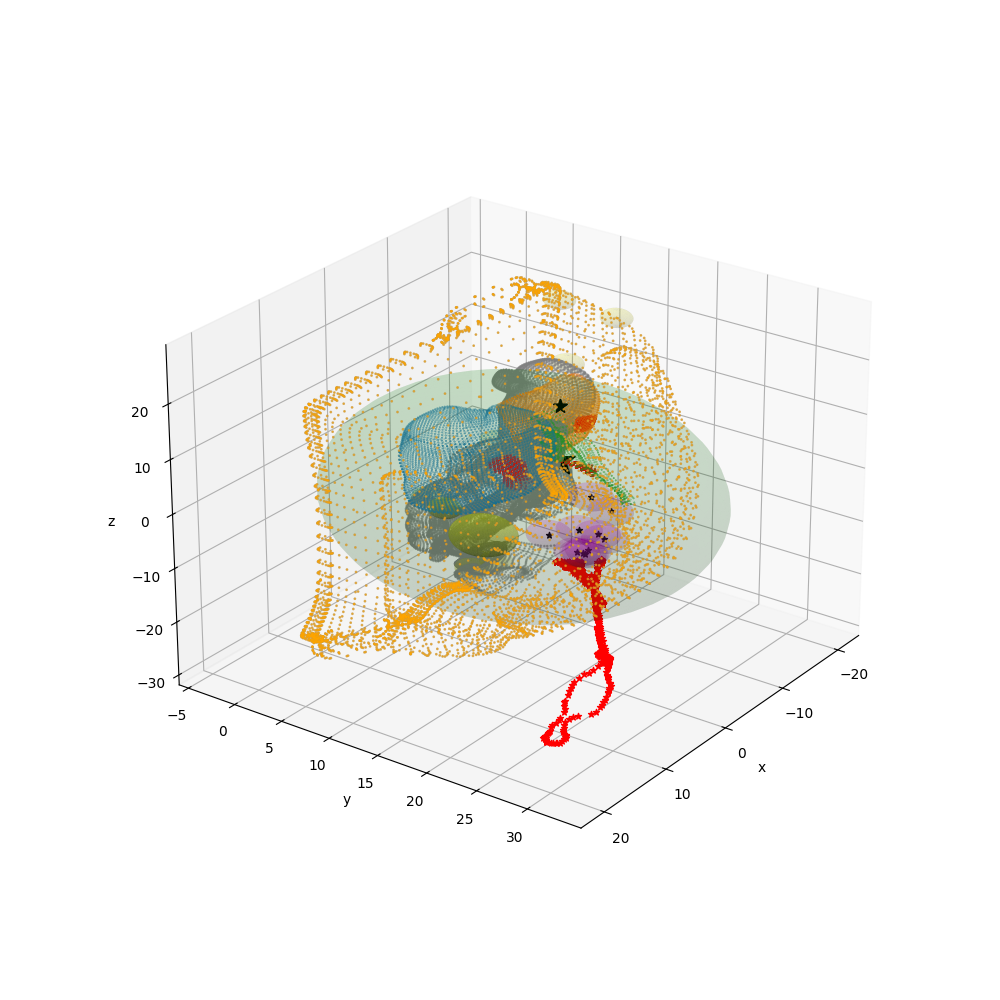

In [36]:
from sklearn.neighbors import NearestNeighbors
fig = plt.figure(figsize=[10,10])
ax = fig.add_subplot(111, projection='3d')
ax.view_init(25, 36)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')


highlight_idx = np.arange(1240,1250)

highlight_index_dict = {}
anatomy_highlight_idx = {'LiverRight.obj': 1500, 'LiverLeft.obj':1072, 'Falciform.obj':700}
sphere_shell_directions = {'LiverRight.obj': [(0.0,np.pi),(np.pi/4,3*np.pi/2),3,12], 'LiverLeft.obj': [(0.0,np.pi),(np.pi/3,3*np.pi/2),8,20], 'Falciform.obj':[(0.0,np.pi),(np.pi/2,3*np.pi/2),3,14]}

for anatomy_key in ['LiverRight.obj', 'LiverLeft.obj', 'Falciform.obj']:
    anatomy = obj_dict[anatomy_key]
    mid_idx = anatomy_highlight_idx[anatomy_key]
    idx = np.arange(mid_idx,mid_idx+20)
    print(anatomy[0].shape)
    X = anatomy[0][idx]
    nbrs = NearestNeighbors(n_neighbors=30, algorithm='ball_tree').fit(anatomy[0])
    distances, indices = nbrs.kneighbors(X)
    print(indices.shape)
    highlight_index_dict[anatomy_key] = indices


idx=indices
c = [0,0,0]
clrs = ['red', 'blue', 'green','magenta', 'cyan']

# plot additional anatomies in gray:
print(obj_dict.keys())

for i, k in enumerate(['ColonRight.obj','ColonTop.obj', 'Stomach.obj', 'GreaterOmentum.obj','ColonLeftRectum.obj', 'Belly.obj', 'DomeOfBladder.obj', 'Uterus.obj']):
    v = obj_dict[k]
    ax.scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2],s=0.8, c='gray', alpha=0.5)
    if 'Belly' in k:
        ax.scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2],s=0.8, c='orange', alpha=0.5)
        #for j in range(len(v[0])):
        #    plt_sphere(ax, [(v[0][j,0],v[0][j,1]+9.8,v[0][j,2])], [2], color='yellow')
    plt_sphere(ax, [(v[0][0,0],v[0][0,1]+9.8,v[0][0,2])], [1.5], color='yellow')
    plt_sphere(ax, [(v[0][1,0],v[0][1,1]+9.8,v[0][1,2])], [1.5], color='yellow')

    
b_cntr = obj_dict['Belly.obj'][1].centroid
plt_sphere(ax, [(b_cntr[0],b_cntr[1]+9.8,b_cntr[2])], [18], color='green')

# TODO: get / color nearest neighbours on mesh via edges? 
for i, k in enumerate(['LiverRight.obj', 'LiverLeft.obj', 'Falciform.obj']):
#for i, k in enumerate(['Falciform.obj']):

    v = obj_dict[k]
    idx = highlight_index_dict[k]
    ax.scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2],s=0.1)
    #for i in range(len(v[0])):
    #    ax.text(v[0][i,0],v[0][i,1]+9.8,v[0][i,2],  '%s' % (str(i)), size=4, zorder=1,  color='k') 

    #mesh_point = (v[0][idx,0],v[0][idx,1]+9.8,v[0][idx,2])
    ax.scatter(v[0][idx,0],v[0][idx,1]+9.8,v[0][idx,2],s=0.8, c='red')

    plt_sphere(ax, [(10,17,0)], [3], color='yellow')

    
    for j in idx[:1,0]:
        print(j)
        # plot a sphere for every red mesh point and build task completion set
        u_range = sphere_shell_directions[k][0]
        v_range = sphere_shell_directions[k][1]
        r1 = sphere_shell_directions[k][2]
        r2 = sphere_shell_directions[k][3]
        #plt_sphere_section(ax, [(v[0][j,0],v[0][j,1]+9.8,v[0][j,2])], [r1], color=clrs[i], u_range = u_range,  v_range = v_range)
        #plt_sphere_section(ax, [(v[0][j,0],v[0][j,1]+9.8,v[0][j,2])], [r2], color=clrs[i], u_range = u_range,  v_range = v_range)

        c = [v[0][j,0],v[0][j,1]+9.8,v[0][j,2]]


plot_traj = True
if plot_traj:
    cnt = 0
    max_n_traj = 10
    #points = {11:[],12:[],13:[],14:[],15:[]}
    a = np.arange(8,18)
    
    points = {}
    for aidx in a:
        points[aidx] = []

    # print trajectory sections corresponding to falciform 
    for k,v in data_dict.items():
        for i, anatomy_idx in enumerate(points.keys()): 
        #for anatomy_idx in [13]:
            liver_states = v[np.where(v[:,-1]==anatomy_idx),:].squeeze()

            print(liver_states.shape)
            #ax.scatter(liver_states[:,0],liver_states[:,1],-liver_states[:,2], s=1.2)
            #ax.plot(liver_states[:,0],liver_states[:,1],-liver_states[:,2])
            
            points[anatomy_idx].extend(liver_states)
            #points.extend(liver_states)
            if anatomy_idx == 14:
                k_ = 'Falciform.obj'
                u_range = sphere_shell_directions[k_][0]
                v_range = sphere_shell_directions[k_][1]
                r1 = sphere_shell_directions[k_][2]
                r2 = sphere_shell_directions[k_][3]
                for state in liver_states:
                    inside = check_inside_shell(np.array([state[0],state[1],-state[2]]), np.array(c), r1, r2, theta_bounds=u_range, phi_bounds=v_range)
                    if not inside:
                        ax.scatter(state[0],state[1],-state[2], s=20, marker='*', c='r')
                        
                    
        cnt += 1
        if cnt > max_n_traj:
            break
            
    #cvx_hull = ConvexHull(points)
    #for simplex in hull.simplices:
        #plt.plot(points[simplex, 0], points[simplex, 1], 'k-')

    for k,v in points.items():
        traj_centroid = np.mean(np.array(v)[:,:3],0)    
        print(traj_centroid)
        ax.scatter(traj_centroid[0], traj_centroid[1], traj_centroid[2], marker='*', s=20,c='k')
        ax.plot(traj_centroid[0], traj_centroid[1], traj_centroid[2], c='k', lw=5)

        plt_sphere(ax, [traj_centroid], [2], color='magenta')

        
r=10
theta = 0
phi = 0
ax.scatter(c[0], c[1], c[2], marker='*', s=500, c='k')
ax.scatter(r*np.sin(theta)*np.cos(phi)+c[0], r*np.sin(theta)*np.sin(phi)+c[1], r*np.cos(theta)+c[2], marker='*', s=100, c='k')
ax.scatter(r*np.sin(theta)*np.cos(phi)+c[0], r*np.sin(theta)*np.sin(phi)+c[1], r*np.cos(theta)+c[2], marker='*', s=100, c='k')

In [ ]:
from sklearn.neighbors import NearestNeighbors
fig = plt.figure(figsize=[10,10])
ax = fig.add_subplot(111, projection='3d')
ax.view_init(-45, 90)
highlight_idx = np.arange(1240,1250)

liver = obj_dict['LiverRight.obj']
idx = np.arange(1230,1260)
X = liver[0][idx]
nbrs = NearestNeighbors(n_neighbors=60, algorithm='ball_tree').fit(liver[0])
distances, indices = nbrs.kneighbors(X)

liver_states = []
for k,v in data_dict.items():
    liver_states.append(v[np.where(v[:,-1]==12),:].squeeze())

print(indices.shape)
idx=indices
# TODO: get / color nearest neighbours on mesh via edges? 
for k,v in obj_dict.items():
    print(k)
    ax.scatter(v[0][:,0],v[0][:,1]+9.8,v[0][:,2],s=0.1)
    #ax.scatter(v[0][idx,0],v[0][idx,1]+9.8,v[0][idx,2],s=0.8, c='red')

offset1 = 1100
offset2 = 1
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
anatomy_list = [
            'DomeOfBladder.obj', 'Uterus.obj', 'CecumAppendix.obj',
            'ColonRight.obj', 'LiverRight.obj', 'Falciform.obj',
            'LiverLeft.obj', 'GallBladder.obj', 'HepatoDuodenalLigament.obj',
            'Spleen.obj', 'Stomach.obj']

cm =sns.color_palette("icefire", as_cmap=True)

for k,v in list(data_dict.items())[:100]:
    if '49ee32c0' in str(k):
        NUM_COLORS = int(np.max(v[:-1]))

    #liver_states = v[np.where(v[:,-1]==12),:].squeeze()
        v = v[offset1:-offset2,:]
        #ax.scatter(v[offset1:-offset2,0],v[offset1:-offset2,1],-v[offset1:-offset2,2], s=1.2)
        #ax.plot(v[offset1:-offset2,0],v[offset1:-offset2,1],-v[offset1:-offset2,2])
                                    
        #ax.set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])

        for i, anatomy in enumerate(anatomy_list):
            v_ = v[np.where(v[:,-1]==i)]

            #print(v_.shape)
            if len(v_) > 1:
                ax.scatter(v_[0,0],v_[0,1],-v_[0,2], s=10, c='k')
            ax.scatter(v_[:,0],v_[:,1],-v_[:,2], s=1.2)
            ax.plot(v_[:,0],v_[:,1],-v_[:,2], label=anatomy)

plt.legend()#loc='upper center', bbox_to_anchor=(0.5, -0.5), fancybox=False, shadow=False, frameon=False, ncol=5)


### Use Sklearn to fit X dimension

### Use GPytorch to fit multioutput GP